# Will this card wheel?

1. **Part 1:** WheelNet: architecture, results across sets, multi-set model, best-card breakdown (was `wheelnet.ipynb`)
2. **Part 2:** QA: the shipped model on test drafts, pick by pick (was `wheelnet_qa.ipynb`)

Each part is self-contained: it has its own setup cell and can be run on its own. Restart the kernel between parts if memory is tight (each loads a full set). The findings are summarised in [WRITEUP.md](../WRITEUP.md).

# Part 1: WheelNet: architecture and fitting strategy

What the wheel model looks like inside, what it is allowed to see, and how it is trained. Sections:

1. Architecture diagram and parameter budget
2. Tensor shapes through one forward pass
3. Attention masks: how "only what the drafter has seen" is enforced
4. Fitting strategy: chronological splits, loss, LR schedule, regularisation, experiment curves
5. Calibration and an example draft
6. Results across sets, and the weekly-retraining experiment (these fill in as runs finish)
7. One wheel model for every set: features-only cards, pretrained on 7 other sets, and day zero
8. Where it matters: accuracy and calibration for the best cards you pass

Needs `data/features/MSH.PremierDraft/` and `results/MSH.PremierDraft/` (from `scripts/build_dataset.py`,
`scripts/train_nn.py`). Everything runs on CPU in about a minute.

In [1]:
import json
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Patch

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from openlane.data import N_PACKS, N_SEATS, load_tensors
from openlane.evaluate import metrics
from openlane.features import wheel_tensors
from openlane.nn import DraftDataset, WheelNet, collate, draft_context

SET, EVENT = "MSH", "PremierDraft"
OUT = ROOT / "results" / f"{SET}.{EVENT}"

# reference categorical palette, fixed order (same as results.ipynb)
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"
GRAY, INK, MUTED, SURFACE, GRID = "#a3a29c", "#0b0b0b", "#52514e", "#fcfcfb", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})

t = load_tensors(SET, EVENT)
passed, back = wheel_tensors(t)
meta = pickle.load(open(ROOT / "data" / "features" / f"{SET}.{EVENT}" / "meta.pkl", "rb"))
ckpt = torch.load(OUT / "models" / "wheelnet.pt", map_location="cpu", weights_only=False)
model = WheelNet(len(t.names), card_feats=ckpt["card_feats"], **ckpt["cfg"]).eval()
model.load_state_dict(ckpt["state"])
print(f"{SET}: {len(t.draft_id):,} drafts, {len(t.names)} cards, {t.n_picks}-card packs; "
      f"model config {ckpt['cfg'] or 'defaults'}")

MSH: 68,609 drafts, 339 cards, 14-card packs; model config defaults


## 1. Architecture

Two stacks share one card-embedding table.

* **History encoder** reads the draft so far as one token per pick (42 for 14-card packs). Each token sums
  the pack shown (count-weighted mean of card embeddings), the card taken, the cards the other seven
  drafters took from a pack that has come back (picks 9-14 only), and a learned position. Self-attention
  is causal, so token *t* sees picks up to *t*.
* **Pack decoder** scores the cards passed at each wheel-eligible pick (picks 1-6 of each pack). A card
  token is its embedding + copy count + which wheel pick this is + a projection of the history state at
  that pick. Each layer does self-attention among the cards in the same pack (they shield each other),
  then cross-attention to the history up to that pick, then a feed-forward block.
* **Card embedding** = a learned vector + a linear map of known attributes (colours, rarity, mana value,
  creature, bonus sheet), so colour information is there from the first step.

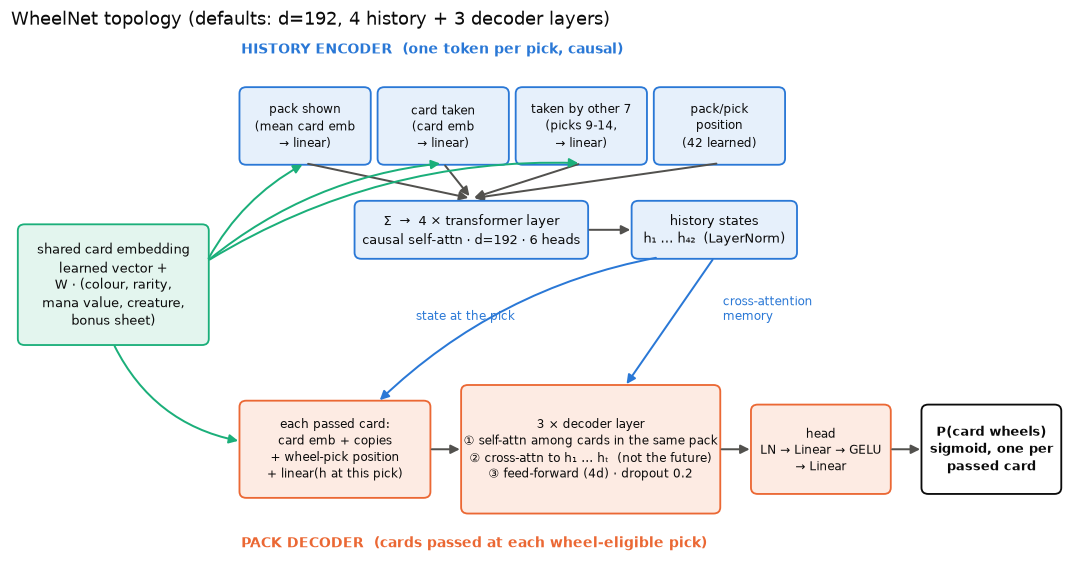

In [2]:
def box(ax, x, y, w, h, text, fc, ec, fs=9, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=fc, ec=ec, lw=1.2))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, color=INK,
            fontweight="bold" if bold else "normal", linespacing=1.35)

def arrow(ax, a, b, color=MUTED, rad=0.0, style="-|>"):
    ax.add_patch(FancyArrowPatch(a, b, arrowstyle=style, mutation_scale=12, color=color, lw=1.3,
                                 connectionstyle=f"arc3,rad={rad}", shrinkA=2, shrinkB=2))

HIST_FC, DEC_FC, EMB_FC = "#e6f0fb", "#fdebe3", "#e3f5ee"
fig, ax = plt.subplots(figsize=(12.5, 6.2))
ax.set_xlim(0, 12.5); ax.set_ylim(-0.3, 6.4); ax.axis("off"); ax.grid(False)

# shared card embedding
box(ax, 0.1, 2.45, 2.2, 1.5, "shared card embedding\nlearned vector +\nW · (colour, rarity,\nmana value, creature,\nbonus sheet)", EMB_FC, AQUA, fs=8.5)

# history lane
ax.text(2.7, 6.15, "HISTORY ENCODER  (one token per pick, causal)", color=BLUE, fontsize=9, fontweight="bold")
ins = ["pack shown\n(mean card emb\n→ linear)", "card taken\n(card emb\n→ linear)",
       "taken by other 7\n(picks 9-14,\n→ linear)", "pack/pick\nposition\n(42 learned)"]
for i, s in enumerate(ins):
    box(ax, 2.7 + i * 1.62, 4.75, 1.5, 0.95, s, HIST_FC, BLUE, fs=8)
    arrow(ax, (3.45 + i * 1.62, 4.75), (5.4, 4.3))
box(ax, 4.05, 3.55, 2.7, 0.7, "Σ  →  4 × transformer layer\ncausal self-attn · d=192 · 6 heads", HIST_FC, BLUE, fs=8.5)
box(ax, 7.3, 3.55, 1.9, 0.7, "history states\nh₁ … h₄₂  (LayerNorm)", HIST_FC, BLUE, fs=8.5)
arrow(ax, (6.75, 3.9), (7.3, 3.9))
for i in range(3):
    arrow(ax, (2.3, 3.5), (3.45 + i * 1.62, 4.75), color=AQUA, rad=-0.15)

# decoder lane
ax.text(2.7, -0.15, "PACK DECODER  (cards passed at each wheel-eligible pick)", color=ORANGE, fontsize=9, fontweight="bold")
box(ax, 2.7, 0.5, 2.2, 1.2, "each passed card:\ncard emb + copies\n+ wheel-pick position\n+ linear(h at this pick)", DEC_FC, ORANGE, fs=8)
box(ax, 5.3, 0.3, 3.0, 1.6, "3 × decoder layer\n① self-attn among cards in the same pack\n② cross-attn to h₁ … hₜ  (not the future)\n③ feed-forward (4d) · dropout 0.2", DEC_FC, ORANGE, fs=8)
box(ax, 8.7, 0.55, 1.6, 1.1, "head\nLN → Linear → GELU\n→ Linear", DEC_FC, ORANGE, fs=8)
box(ax, 10.7, 0.55, 1.6, 1.1, "P(card wheels)\nsigmoid, one per\npassed card", "#ffffff", INK, fs=8.5, bold=True)
arrow(ax, (4.9, 1.1), (5.3, 1.1)); arrow(ax, (8.3, 1.1), (8.7, 1.1)); arrow(ax, (10.3, 1.1), (10.7, 1.1))
arrow(ax, (1.2, 2.45), (2.7, 1.2), color=AQUA, rad=0.25)
arrow(ax, (8.25, 3.55), (7.2, 1.9), color=BLUE, rad=0.0)       # cross-attention memory
arrow(ax, (7.6, 3.55), (4.3, 1.7), color=BLUE, rad=0.15)       # ctx(state)
ax.text(8.35, 2.75, "cross-attention\nmemory", color=BLUE, fontsize=8)
ax.text(4.75, 2.75, "state at the pick", color=BLUE, fontsize=8)
ax.set_title("WheelNet topology (defaults: d=192, 4 history + 3 decoder layers)", loc="left", color=INK)
plt.show()

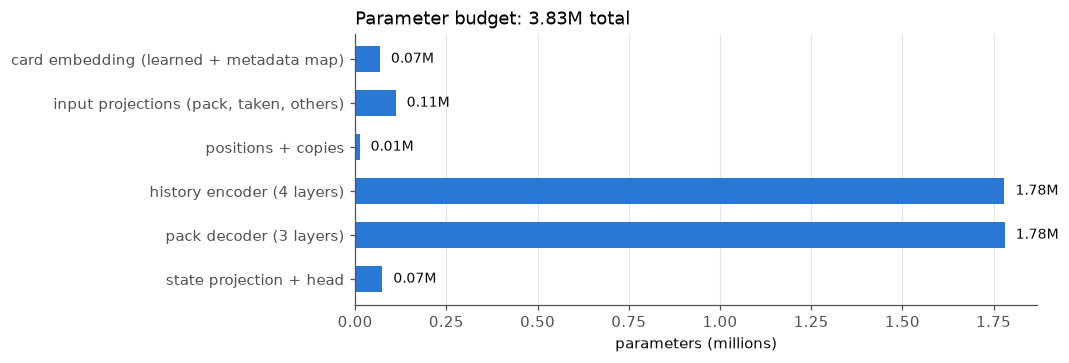

In [3]:
groups = {
    "card embedding (learned + metadata map)": ["card_", "feat_proj"],
    "input projections (pack, taken, others)": ["bag", "others", "taken"],
    "positions + copies": ["pos", "pick_pos", "copies"],
    "history encoder (4 layers)": ["hist", "hist_norm"],
    "pack decoder (3 layers)": ["packenc"],
    "state projection + head": ["ctx", "head"],
}
counts = {g: sum(p.numel() for n, p in model.named_parameters() if n.split(".")[0] in mods)
          for g, mods in groups.items()}
assert sum(counts.values()) == sum(p.numel() for p in model.parameters())
fig, ax = plt.subplots(figsize=(8, 3.2))
names, vals = list(counts)[::-1], [counts[g] / 1e6 for g in list(counts)[::-1]]
ax.barh(names, vals, color=BLUE, height=0.6)
for i, v in enumerate(vals):
    ax.text(v + 0.03, i, f"{v:.2f}M", va="center", color=INK, fontsize=9)
ax.set_xlabel("parameters (millions)"); ax.grid(axis="y", visible=False)
ax.set_title(f"Parameter budget: {sum(counts.values())/1e6:.2f}M total", loc="left")
plt.show()

## 2. Shapes through one forward pass

A batch of 4 real drafts, with hooks on each stage. `B` = drafts, 42 = picks, 18 = wheel-eligible picks
(3 packs × 6), 13 = the most distinct cards a passed pack can hold, 234 = 18 × 13 card slots per draft.
Packs are stored sparsely: each pick is a list of up to 14 distinct card ids with counts, not a 339-wide
vector.

In [4]:
test_idx = meta["splits"]["test"]
ds = DraftDataset(t, passed, back, test_idx[:64],
                 draft_context(t, **ckpt["inputs"]) if "inputs" in ckpt else None)
batch = collate([ds[i] for i in range(4)])
names_in = ["pack ids", "pack counts", "others ids", "others counts", "pick", "passed card ids",
            "copies", "label", "mask", "draft context"]
rows = [{"stage": f"input: {n}", "shape": str(tuple(x.shape)), "dtype": str(x.dtype).replace("torch.", "")}
        for n, x in zip(names_in, batch)]
seen = []
hooks = [getattr(model, m).register_forward_hook(
    lambda mod, i, o, m=m: seen.append({"stage": m, "shape": str(tuple(o.shape)), "dtype": str(o.dtype).replace("torch.", "")}))
    for m in ["hist", "packenc", "head"]]
*x, label, mask, ctx = batch
with torch.no_grad():
    out = model(*x, mask, ctx)
for h in hooks:
    h.remove()
labels = {"hist": "history encoder output", "packenc": "pack decoder output (18 packs × 13 slots, flattened)",
          "head": "head output"}
rows += [{**r, "stage": labels[r["stage"]]} for r in seen]
rows.append({"stage": "logits (per draft, pack, wheel pick, card slot)", "shape": str(tuple(out.shape)), "dtype": "float32"})
pl.Config.set_tbl_rows(20); pl.Config.set_fmt_str_lengths(60)
pl.DataFrame(rows)

stage,shape,dtype
str,str,str
"""input: pack ids""","""(4, 42, 14)""","""int16"""
"""input: pack counts""","""(4, 42, 14)""","""int8"""
"""input: others ids""","""(4, 42, 13)""","""int16"""
"""input: others counts""","""(4, 42, 13)""","""int8"""
"""input: pick""","""(4, 42)""","""int64"""
"""input: passed card ids""","""(4, 3, 6, 13)""","""int64"""
"""input: copies""","""(4, 3, 6, 13)""","""int64"""
"""input: label""","""(4, 3, 6, 13)""","""bool"""
"""input: mask""","""(4, 3, 6, 13)""","""bool"""


## 3. Attention masks: what the model may look at

Leakage is prevented structurally, by masks, not by feature engineering. Blue cells may attend; pale
cells are blocked.

* **History self-attention** is causal: pick *t* sees picks ≤ *t*.
* **Cross-attention** from the cards passed at a wheel pick sees history up to and including that pick
  (you know what you just took), never the returning pack.
* **Pack self-attention** is block-diagonal: the 18 packs of a draft share one sequence for speed, but
  cards only attend to cards in their own pack.

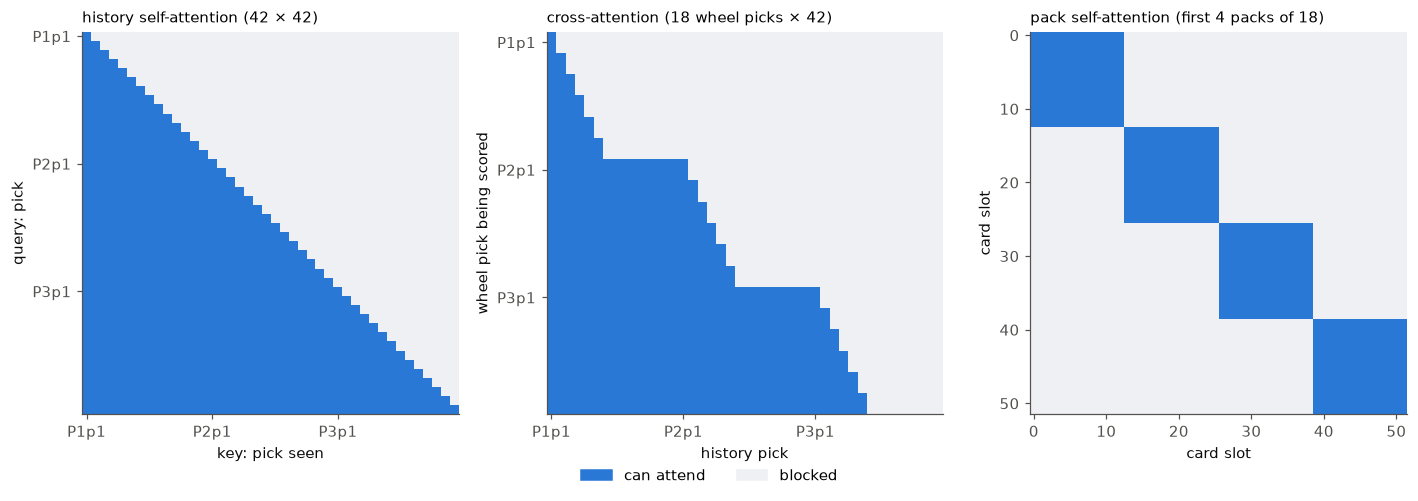

In [5]:
from matplotlib.colors import ListedColormap
cm = ListedColormap(["#eef0f3", BLUE])
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1, 1.05, 1]})
T = N_PACKS * t.n_picks
panels = [
    (~model.causal.numpy(), "history self-attention (42 × 42)", "key: pick seen", "query: pick"),
    (~model.future_tok.numpy()[::model.max_pass], "cross-attention (18 wheel picks × 42)", "history pick", "wheel pick being scored"),
    (~model.block.numpy()[:4 * model.max_pass, :4 * model.max_pass], "pack self-attention (first 4 packs of 18)", "card slot", "card slot"),
]
for ax, (m, title, xl, yl) in zip(axes, panels):
    ax.imshow(m, cmap=cm, interpolation="nearest", aspect="auto")
    ax.set_title(title, loc="left", fontsize=10); ax.set_xlabel(xl); ax.set_ylabel(yl); ax.grid(False)
for ax in axes[:2]:
    ax.set_xticks([k * t.n_picks for k in range(3)], ["P1p1", "P2p1", "P3p1"])
axes[0].set_yticks([k * t.n_picks for k in range(3)], ["P1p1", "P2p1", "P3p1"])
axes[1].set_yticks([k * model.W for k in range(3)], ["P1p1", "P2p1", "P3p1"])
fig.legend(handles=[Patch(color=BLUE, label="can attend"), Patch(color="#eef0f3", label="blocked")],
           loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(); plt.show()

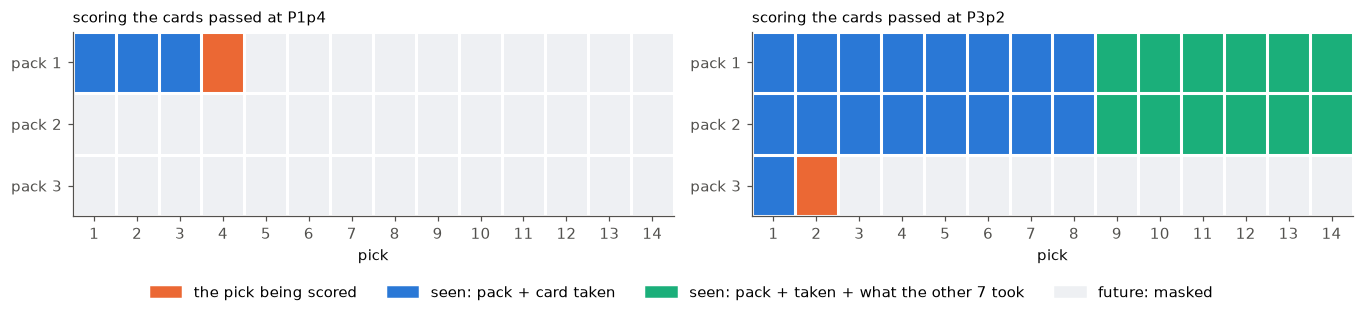

In [6]:
def visibility(k_scored, p_scored):
    """Category of every history token when scoring pack k_scored, pick p_scored."""
    g = np.zeros((N_PACKS, t.n_picks), int)            # 0 hidden (future)
    for k in range(N_PACKS):
        for p in range(t.n_picks):
            if (k, p) <= (k_scored, p_scored):
                g[k, p] = 2 if p >= N_SEATS else 1   # 2 = also carries "taken by other 7"
    g[k_scored, p_scored] = 3
    return g

cmap4 = ListedColormap(["#eef0f3", BLUE, AQUA, ORANGE])
fig, axes = plt.subplots(1, 2, figsize=(12.5, 2.6))
for ax, (k, p) in zip(axes, [(0, 3), (2, 1)]):
    ax.imshow(visibility(k, p), cmap=cmap4, vmin=0, vmax=3, aspect="auto")
    ax.set_xticks(range(t.n_picks), [str(i + 1) for i in range(t.n_picks)])
    ax.set_yticks(range(3), ["pack 1", "pack 2", "pack 3"]); ax.set_xlabel("pick")
    ax.set_xticks(np.arange(-.5, t.n_picks), minor=True); ax.set_yticks(np.arange(-.5, 3), minor=True)
    ax.grid(which="minor", color="white", lw=2); ax.grid(which="major", visible=False)
    ax.tick_params(which="minor", length=0)
    ax.set_title(f"scoring the cards passed at P{k+1}p{p+1}", loc="left", fontsize=10)
fig.legend(handles=[Patch(color=ORANGE, label="the pick being scored"), Patch(color=BLUE, label="seen: pack + card taken"),
                    Patch(color=AQUA, label="seen: pack + taken + what the other 7 took"),
                    Patch(color="#eef0f3", label="future: masked")], loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.show()

## 4. Fitting strategy

| | |
|---|---|
| **Split** | chronological: first 70% of drafts train, next 15% validation, last 15% test. No draft appears in two splits, and the test period is strictly later than training. |
| **Loss** | binary cross-entropy over every real (non-padding) passed card at every wheel-eligible pick |
| **Optimiser** | AdamW, weight decay 0.01, batch 128 drafts, gradient-norm clip 1.0 |
| **Schedule** | one-cycle: 5% linear warm-up to 1e-3, cosine decay to ~0 over 8 epochs |
| **Regularisation** | dropout 0.2 in every attention and feed-forward block |
| **Model selection** | keep the epoch with the best validation log loss; the test set is scored once at the end |
| **Architecture search** | done on validation only (`val_only=1`); see the curves below |

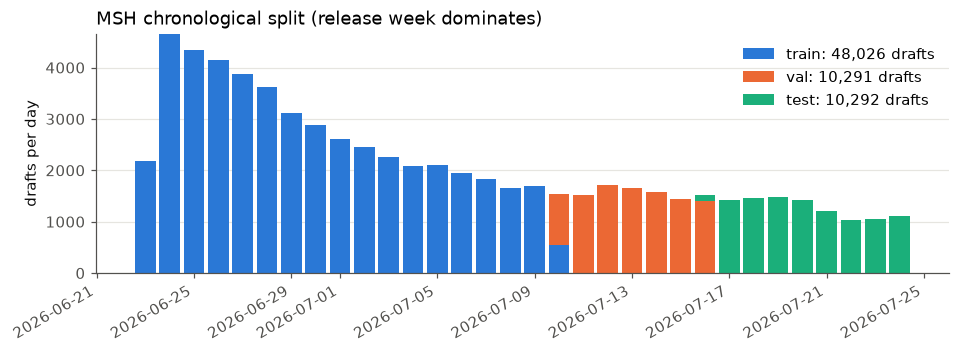

In [7]:
dt = np.array(meta["draft_time"], dtype="datetime64[D]")
days = np.arange(dt.min(), dt.max() + np.timedelta64(1, "D"))
fig, ax = plt.subplots(figsize=(10, 3.2))
bottom = np.zeros(len(days))
for (name, idx), color in zip(meta["splits"].items(), [BLUE, ORANGE, AQUA]):
    n = np.array([(dt[idx] == d).sum() for d in days])
    ax.bar(days, n, bottom=bottom, color=color, width=0.85, label=f"{name}: {len(idx):,} drafts")
    bottom += n
ax.set_ylabel("drafts per day"); ax.legend(loc="upper right"); ax.grid(axis="x", visible=False)
ax.set_title(f"{SET} chronological split (release week dominates)", loc="left")
fig.autofmt_xdate(); plt.show()

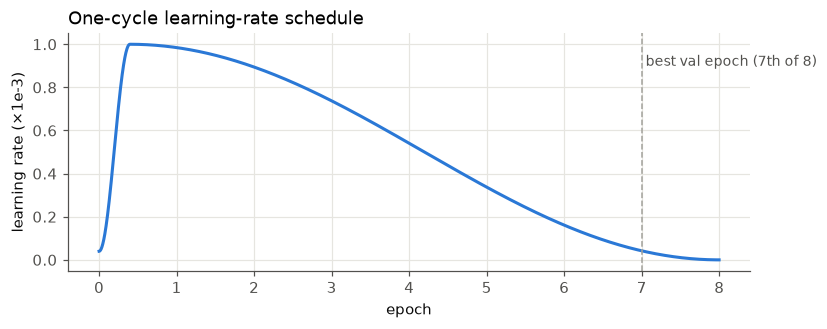

In [8]:
steps_per_epoch = int(np.ceil(len(meta["splits"]["train"]) / 128))
opt = torch.optim.AdamW([torch.nn.Parameter(torch.zeros(1))], lr=1e-3)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=1e-3, total_steps=8 * steps_per_epoch, pct_start=0.05)
lrs = []
for _ in range(8 * steps_per_epoch):
    lrs.append(sched.get_last_lr()[0]); opt.step(); sched.step()
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot(np.arange(len(lrs)) / steps_per_epoch, np.array(lrs) * 1e3, color=BLUE)
ax.axvline(7, color=GRAY, ls="--", lw=1)
ax.text(7.05, 0.9, "best val epoch (7th of 8)", color=MUTED, fontsize=9)
ax.set_xlabel("epoch"); ax.set_ylabel("learning rate (×1e-3)")
ax.set_title("One-cycle learning-rate schedule", loc="left"); plt.show()

### Experiment curves (MSH validation set, this round of changes)

Each line is one training run, scored on the validation drafts after every epoch. The dashed line is
the previous WheelNet's best (0.4293). The first run (dropout 0.1, 12 epochs planned) was stopped once it
began to overfit.

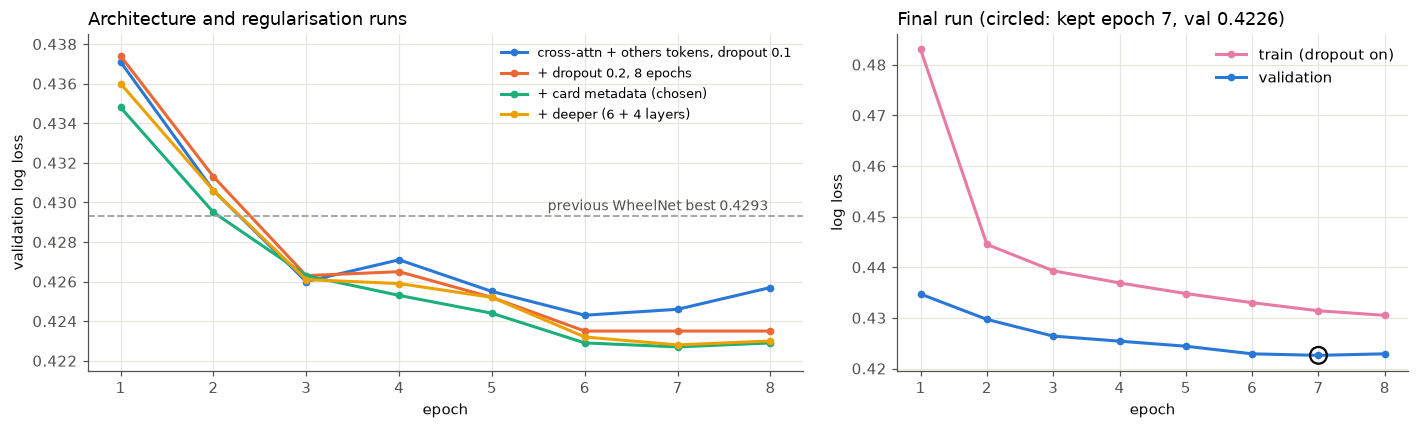

In [9]:
runs = {  # (train loss with dropout on, validation log loss) per epoch, from the training logs
    "cross-attn + others tokens, dropout 0.1": [(0.4869,0.4371),(0.4465,0.4306),(0.4400,0.4260),(0.4371,0.4271),(0.4351,0.4255),(0.4330,0.4243),(0.4308,0.4246),(0.4279,0.4257)],
    "+ dropout 0.2, 8 epochs": [(0.4837,0.4374),(0.4481,0.4313),(0.4415,0.4263),(0.4381,0.4265),(0.4360,0.4252),(0.4339,0.4235),(0.4323,0.4235),(0.4313,0.4235)],
    "+ card metadata (chosen)": [(0.4830,0.4348),(0.4445,0.4295),(0.4393,0.4263),(0.4369,0.4253),(0.4348,0.4244),(0.4330,0.4229),(0.4314,0.4227),(0.4305,0.4229)],
    "+ deeper (6 + 4 layers)": [(0.4834,0.4360),(0.4457,0.4306),(0.4397,0.4261),(0.4373,0.4259),(0.4353,0.4252),(0.4335,0.4232),(0.4320,0.4228),(0.4312,0.4230)],
}
final = [(0.4830,0.4347),(0.4445,0.4297),(0.4393,0.4264),(0.4369,0.4254),(0.4348,0.4244),(0.4330,0.4229),(0.4314,0.4226),(0.4305,0.4229)]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1.4, 1]})
for (name, h), c in zip(runs.items(), [BLUE, ORANGE, AQUA, YELLOW]):
    v = [e[1] for e in h]
    a1.plot(range(1, len(v) + 1), v, color=c, marker="o", ms=4, label=name)
a1.axhline(0.4293, color=GRAY, ls="--", lw=1.2)
a1.text(5.6, 0.4296, "previous WheelNet best 0.4293", color=MUTED, fontsize=9)
a1.set_ylim(0.4215, 0.4385); a1.set_xlabel("epoch"); a1.set_ylabel("validation log loss")
a1.set_title("Architecture and regularisation runs", loc="left"); a1.legend(fontsize=8.5)
a2.plot(range(1, 9), [e[0] for e in final], color=MAGENTA, marker="o", ms=4, label="train (dropout on)")
a2.plot(range(1, 9), [e[1] for e in final], color=BLUE, marker="o", ms=4, label="validation")
best = int(np.argmin([e[1] for e in final]))
a2.scatter([best + 1], [final[best][1]], s=120, facecolor="none", edgecolor=INK, lw=1.5, zorder=5)
a2.set_xlabel("epoch"); a2.set_ylabel("log loss"); a2.legend()
a2.set_title(f"Final run (circled: kept epoch {best+1}, val {final[best][1]:.4f})", loc="left")
plt.tight_layout(); plt.show()

### Input ablation (`results/inputs_ablation.sh`)

Which of the optional inputs earn their place? Each run starts from the bare model (card colour/rarity/mana
value only, no draft context) and adds one group: card types and supertypes, the drafter's rank and 17Lands
skill buckets, or days into the format. MSH validation, 8 epochs each, `val_only=1`.

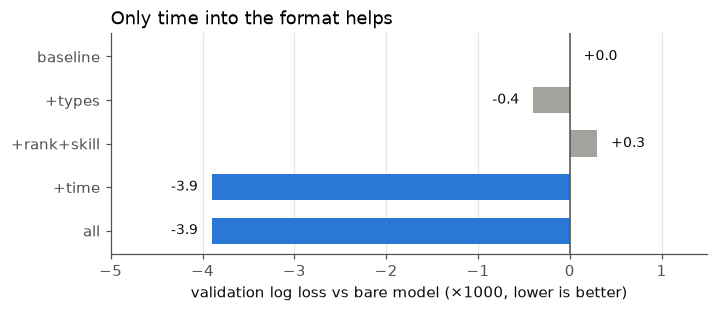

inputs,val log loss,vs bare model
str,f64,f64
"""baseline""",0.4226,0.0
"""+types""",0.4222,-0.0004
"""+rank+skill""",0.4229,0.0003
"""+time""",0.4187,-0.0039
"""all""",0.4187,-0.0039


In [10]:
import re
log = (ROOT / "results" / "inputs_ablation.log").read_text()
names = re.findall(r"^=== (.+)$", log, re.M)
vals = [float(v) for v in re.findall(r"best val_logloss=([0-9.]+)", log)]
abl = pl.DataFrame({"inputs": names, "val log loss": vals}).with_columns(
    (pl.col("val log loss") - vals[0]).alias("vs bare model"))
fig, ax = plt.subplots(figsize=(7, 2.6))
yy = np.arange(abl.height)[::-1]
ax.barh(yy, abl["vs bare model"] * 1000, color=[BLUE if v < -0.001 else GRAY for v in abl["vs bare model"]], height=0.6)
for y, v in zip(yy, abl["vs bare model"]):
    ax.text(v * 1000 + (0.15 if v >= 0 else -0.15), y, f"{v * 1000:+.1f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=9, color=INK)
ax.axvline(0, color=MUTED, lw=1)
ax.set_yticks(yy, abl["inputs"]); ax.set_xlim(-5, 1.5); ax.grid(axis="y", visible=False)
ax.set_xlabel("validation log loss vs bare model (×1000, lower is better)")
ax.set_title("Only time into the format helps", loc="left")
plt.show()
abl

Days into the format is the one input that matters (−3.9 ×10⁻³). Early in a set, drafters take different cards
and the table reads differently; the model uses the date to know which regime it is in. Rank and skill add
nothing once the model sees the drafter's picks, which already show how they draft. Card types are a wash with
learned card embeddings. The shipped `wheelnet_time` model uses time only (test 0.4218 vs 0.4249 for the earlier
`wheelnet`); `wheel.ipynb` part 2 §6 shows what the time input does to predictions.

## 5. Calibration and an example draft

Calibration on the held-out test drafts: predictions are binned into 20 equal-count bins, and each dot
compares the mean predicted probability with the observed wheel rate. Points on the diagonal mean a
predicted 30% really wheels about 30% of the time.

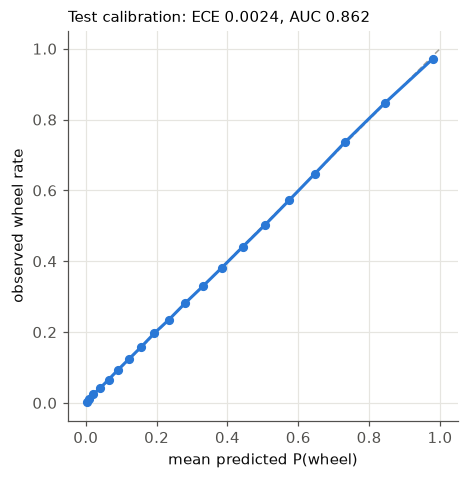

In [11]:
pred = pl.read_parquet(OUT / "test_predictions_wheelnet.parquet")
p, y = pred["wheelnet"].to_numpy(), pred["wheeled"].to_numpy()
q = np.quantile(p, np.linspace(0, 1, 21)); b = np.clip(np.searchsorted(q, p, side="right") - 1, 0, 19)
mp = np.bincount(b, p) / np.bincount(b); my = np.bincount(b, y) / np.bincount(b)
m = metrics(y, p)
fig, ax = plt.subplots(figsize=(4.8, 4.6))
ax.plot([0, 1], [0, 1], color=GRAY, lw=1, ls="--")
ax.plot(mp, my, color=BLUE, marker="o", ms=5)
ax.set_xlabel("mean predicted P(wheel)"); ax.set_ylabel("observed wheel rate")
ax.set_title(f"Test calibration: ECE {m['ece']:.4f}, AUC {m['auc']:.3f}", loc="left", fontsize=10)
ax.set_aspect("equal"); plt.show()

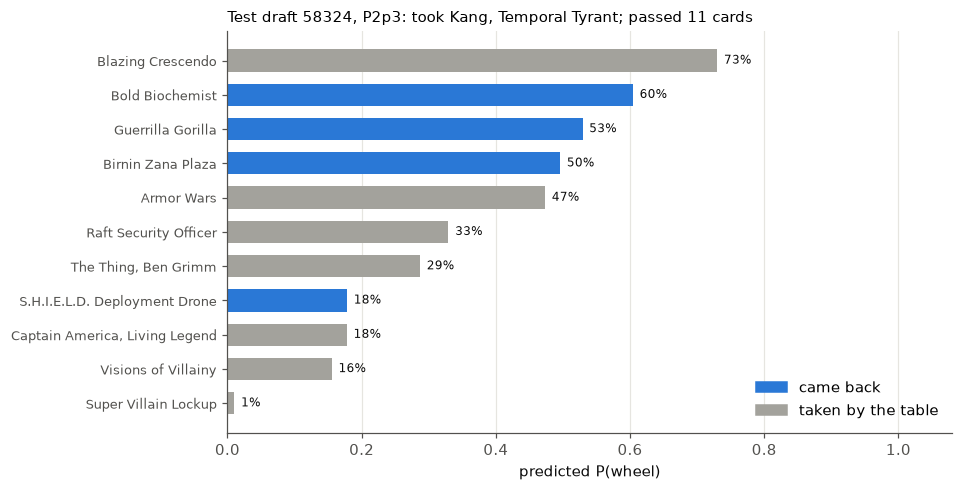

In [12]:
# one test draft, the cards passed at pack 2 pick 3
d, k, pk = 7, 1, 2
x = collate([ds[d]])
with torch.no_grad():
    prob = torch.sigmoid(model(*x[:7], x[8], x[9]))[0, k, pk].numpy()
msk, idx, lab = ds.mask[d, k, pk], ds.idx[d, k, pk], ds.label[d, k, pk]
order = np.argsort(prob[msk])
cards = [t.names[c] for c in idx[msk]]
fig, ax = plt.subplots(figsize=(8.5, 0.34 * msk.sum() + 1))
colors = [BLUE if w else GRAY for w in lab[msk][order]]
ax.barh(range(len(order)), prob[msk][order], color=colors, height=0.65)
ax.set_yticks(range(len(order)), [cards[i] for i in order], fontsize=8.5)
for i, v in enumerate(prob[msk][order]):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=8, color=INK)
ax.set_xlim(0, 1.08); ax.set_xlabel("predicted P(wheel)"); ax.grid(axis="y", visible=False)
taken = t.names[t.pick[test_idx[d], k, pk]]
ax.set_title(f"Test draft {test_idx[d]}, P{k+1}p{pk+1}: took {taken}; passed {msk.sum()} cards", loc="left", fontsize=10)
ax.legend(handles=[Patch(color=BLUE, label="came back"), Patch(color=GRAY, label="taken by the table")],
          loc="lower right")
plt.show()

## 6. Results across sets

Each set is trained and tested the same way as MSH (`scripts/run_all_sets.sh`). WheelNet gets fewer
epochs on bigger sets (`round(8 × 48k / training drafts)`, clamped to 3-8). The GBM and ALSA baseline are
fit on at most the 60k most recent training drafts to fit in 16GB. Bars show the relative log-loss
reduction against the ALSA/ATA baseline. Sets still running are skipped.

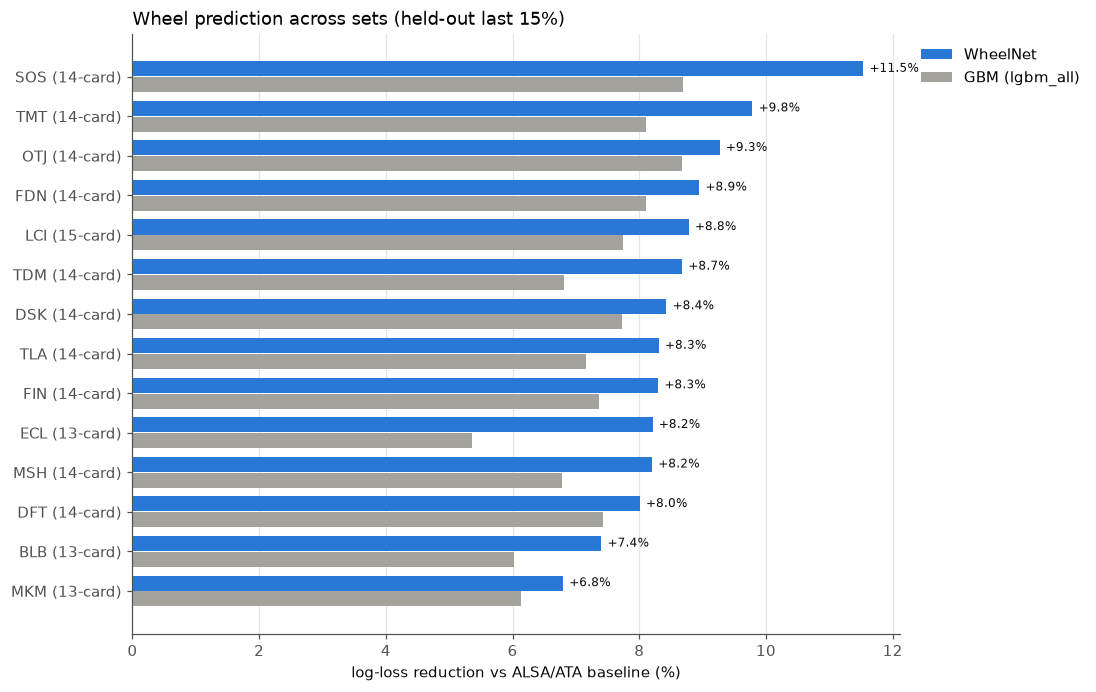

set,drafts,pack,alsa_logloss,lgbm_all,wheelnet,wheelnet_logloss,wheelnet_auc
str,i64,i64,f64,f64,f64,f64,f64
"""BLB""",154585,13,0.499128,0.060234,0.073998,0.462193,0.821076
"""DFT""",141166,14,0.460812,0.074234,0.080062,0.423919,0.861754
"""DSK""",167672,14,0.454199,0.077284,0.084264,0.415927,0.868064
"""ECL""",99289,13,0.491092,0.053612,0.082086,0.45078,0.826016
"""FDN""",130935,14,0.461429,0.081001,0.089453,0.420153,0.86526
"""FIN""",140237,14,0.477094,0.073649,0.08297,0.437509,0.85285
"""LCI""",134970,15,0.486049,0.077429,0.087784,0.443382,0.857767
"""MKM""",157553,13,0.481418,0.061345,0.067935,0.448713,0.833177
"""MSH""",68609,14,0.462869,0.067726,0.081992,0.424917,0.861826


In [13]:
rows = []
for f in sorted((ROOT / "results").glob("*.PremierDraft/summary.json")):
    s = {r["model"]: r for r in json.load(open(f))}
    if "wheelnet" not in s:
        continue
    fm = pickle.load(open(ROOT / "data" / "features" / f.parent.name / "meta.pkl", "rb"))
    rows.append({"set": f.parent.name.split(".")[0], "drafts": len(fm["draft_id"]),
                 "pack": fm.get("n_picks", 14), "alsa_logloss": s["alsa_ata_logreg"]["logloss"],
                 "lgbm_all": s["lgbm_all"]["vs_alsa"], "wheelnet": s["wheelnet"]["vs_alsa"],
                 "wheelnet_logloss": s["wheelnet"]["logloss"], "wheelnet_auc": s["wheelnet"]["auc"]})
sets = pl.DataFrame(rows).sort("wheelnet")
fig, ax = plt.subplots(figsize=(9, 0.42 * sets.height + 1.2))
yy = np.arange(sets.height)
ax.barh(yy + 0.2, sets["wheelnet"] * 100, height=0.38, color=BLUE, label="WheelNet")
ax.barh(yy - 0.2, sets["lgbm_all"] * 100, height=0.38, color=GRAY, label="GBM (lgbm_all)")
for i, v in enumerate(sets["wheelnet"]):
    ax.text(v * 100 + 0.1, i + 0.2, f"{v:+.1%}", va="center", fontsize=8, color=INK)
ax.set_yticks(yy, [f"{s} ({p}-card)" for s, p in zip(sets["set"], sets["pack"])])
ax.set_xlabel("log-loss reduction vs ALSA/ATA baseline (%)"); ax.grid(axis="y", visible=False)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1)); ax.set_title("Wheel prediction across sets (held-out last 15%)", loc="left")
plt.show()
sets.sort("set")

### Weekly retraining (`scripts/temporal.py SET`)

Each line is scored on one week's drafts, using only earlier weeks for training. `frozen` never sees
anything after week 1; `retrain` starts over on everything so far; `finetune` / `replay` warm-start from
last week's model. The lookup arms show how much the raw card-level wheel rates drift.

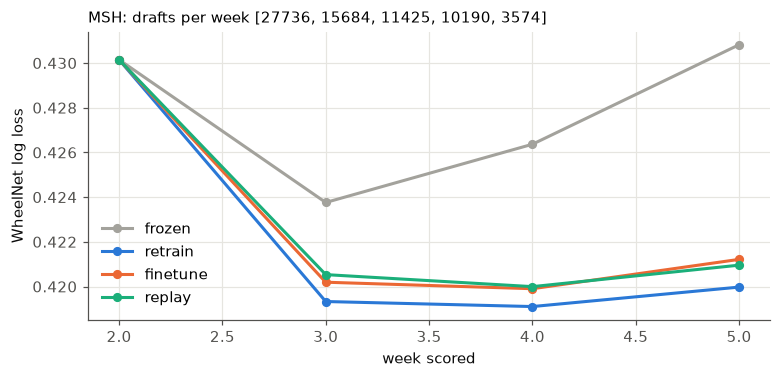

In [14]:
files = sorted((ROOT / "results").glob("*.PremierDraft/temporal.json"))
if not files:
    print("no temporal.json yet: run  python scripts/temporal.py MSH")
for f in files:
    r = json.load(open(f))
    fig, ax = plt.subplots(figsize=(8, 3.4))
    arms = [("frozen", GRAY), ("retrain", BLUE), ("finetune", ORANGE), ("replay", AQUA)]
    for arm, c in arms:
        w = sorted(r["arms"][arm], key=int)
        ax.plot([int(i) + 1 for i in w], [r["arms"][arm][i]["logloss"] for i in w], color=c, marker="o", ms=5, label=arm)
    ax.set_xlabel("week scored"); ax.set_ylabel("WheelNet log loss")
    ax.set_title(f"{f.parent.name.split('.')[0]}: drafts per week {r['weeks']}", loc="left", fontsize=10)
    ax.legend(); plt.show()

In [15]:
r = json.load(open(OUT / "temporal.json"))
weeks = sorted(r["arms"]["retrain"], key=int)
gap = pl.DataFrame({"week scored": [int(w) + 1 for w in weeks],
                    "drafts": [r["weeks"][int(w)] for w in weeks],
                    **{arm: [r["arms"][arm][w]["logloss"] for w in weeks] for arm in r["arms"]}})
gap.with_columns(*[(pl.col(a) - pl.col("retrain")).round(4).alias(f"{a} − retrain")
                   for a in ("frozen", "finetune", "replay")])

week scored,drafts,lookup_frozen,lookup_refit,retrain,frozen,finetune,replay,frozen − retrain,finetune − retrain,replay − retrain
i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2,15684,0.466287,0.466287,0.430147,0.430147,0.430147,0.430147,0.0,0.0,0.0
3,11425,0.465219,0.459829,0.419328,0.42376,0.420192,0.420532,0.0044,0.0009,0.0012
4,10190,0.465971,0.457405,0.419103,0.426365,0.419901,0.419994,0.0073,0.0008,0.0009
5,3574,0.469146,0.458506,0.419974,0.430818,0.421214,0.420955,0.0108,0.0012,0.001


What the weekly walk-forward shows (MSH; week 1 is training only, so scoring starts at week 2):
1. **A frozen model goes stale, and the gap keeps growing.** Trained on week 1 only, it falls behind a weekly
   retrain by 0.0044, 0.0073 and 0.0108 log loss in weeks 3, 4 and 5. The frozen per-card lookup drifts the same
   way (0.466 → 0.469) while a refit lookup improves. The format really changes: what people take, and so what
   wheels, keeps moving for weeks after release.
2. **Retraining from scratch is best every week, but fine-tuning is nearly as good.** Two epochs on last week's
   drafts (`finetune`) stay about 0.001 behind a full retrain, and mixing in older drafts (`replay`) adds
   nothing. For a live tool, a cheap weekly fine-tune is enough.
3. **Staying current matters as much as the architecture.** By week 5 the frozen model's staleness (0.011)
   costs more than WheelNet's whole advantage over the GBM on the test set (0.0066).

## 7. One wheel model for every set (`scripts/train_wheelnet_multiset.py`)

The per-set WheelNet learns one embedding per card, so it can only score a set it was trained on. With
`ids=False` a card is *only* its features: colour, rarity, mana value, types, Scryfall rules features and a
frozen rules-text embedding (465 numbers), mapped by an MLP into the same 192-d slot. One set of weights then
scores any set. The training data is 20k random drafts from each of the 7 other 14-card sets (OTJ DSK FDN DFT TDM
FIN SOS), and optionally MSH's own training drafts. 5% is held out for early stopping, 4 epochs, otherwise the
same recipe as §4. The pick model got its best result this way (`drafting.ipynb`).

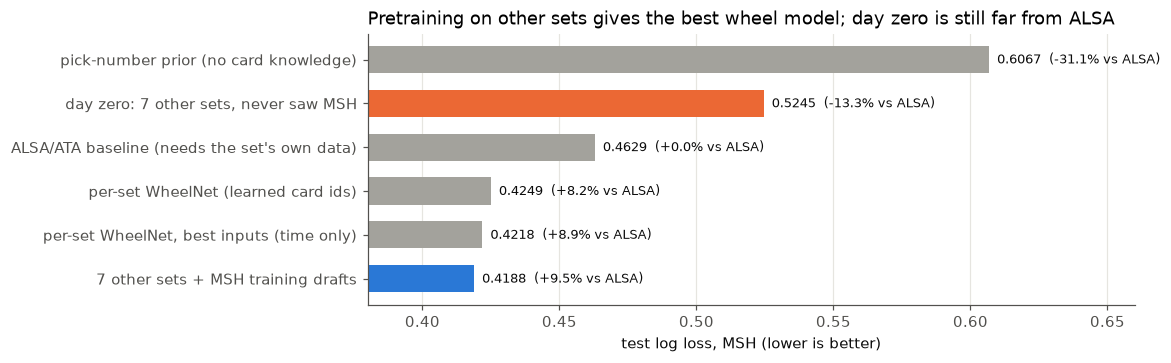

model,logloss,auc,ece,vs ALSA
str,f64,f64,f64,f64
"""pick-number prior (no card knowledge)""",0.606722,0.638899,0.000003,-0.310785
"""day zero: 7 other sets, never saw MSH""",0.524493,0.776397,0.048351,-0.133134
"""ALSA/ATA baseline (needs the set's own data)""",0.462869,0.83086,0.007331,0.0
"""per-set WheelNet (learned card ids)""",0.424917,0.861826,0.00236,0.081992
"""per-set WheelNet, best inputs (time only)""",0.42181,0.864416,0.007473,0.088705
"""7 other sets + MSH training drafts""",0.418773,0.866318,0.003005,0.095267


In [16]:
names = {"prior_by_pick": "pick-number prior (no card knowledge)",
         "wheelnet_multiset_zeroshot": "day zero: 7 other sets, never saw MSH",
         "alsa_ata_logreg": "ALSA/ATA baseline (needs the set's own data)",
         "wheelnet": "per-set WheelNet (learned card ids)",
         "wheelnet_time": "per-set WheelNet, best inputs (time only)",
         "wheelnet_multiset_plus_target": "7 other sets + MSH training drafts"}
base = json.load(open(OUT / "results.json"))["test"]
res = {k: (base[k] if k in base else json.load(open(OUT / f"results_{k}.json"))) for k in names}
alsa = res["alsa_ata_logreg"]["logloss"]
tab = pl.DataFrame([{"model": names[k], "logloss": r["logloss"], "auc": r["auc"], "ece": r["ece"],
                     "vs ALSA": 1 - r["logloss"] / alsa} for k, r in res.items()])

fig, ax = plt.subplots(figsize=(9, 3.2))
yy = np.arange(len(names))[::-1]
best = "wheelnet_multiset_plus_target"
colors = [BLUE if k == best else (ORANGE if k == "wheelnet_multiset_zeroshot" else GRAY) for k in names]
ax.barh(yy, tab["logloss"], color=colors, height=0.62)
for y, v, d in zip(yy, tab["logloss"], tab["vs ALSA"]):
    ax.text(v + 0.003, y, f"{v:.4f}  ({d:+.1%} vs ALSA)", va="center", fontsize=8.5, color=INK)
ax.set_yticks(yy, tab["model"]); ax.set_xlim(0.38, 0.66); ax.grid(axis="y", visible=False)
ax.set_xlabel("test log loss, MSH (lower is better)")
ax.set_title("Pretraining on other sets gives the best wheel model; day zero is still far from ALSA", loc="left")
plt.show()
tab

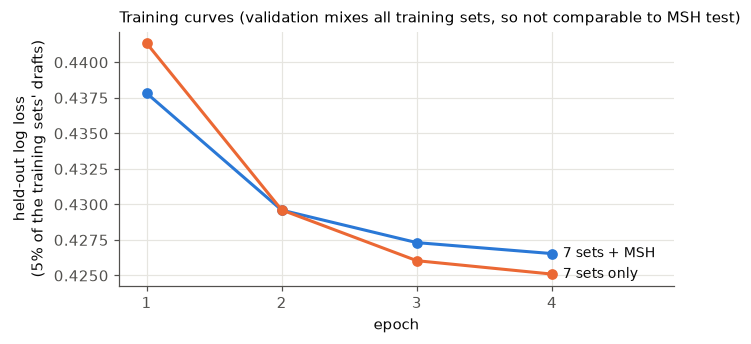

In [17]:
hist = {k: json.load(open(OUT / f"results_{k}.json"))["history"] for k in ("wheelnet_multiset_plus_target", "wheelnet_multiset_zeroshot")}
fig, ax = plt.subplots(figsize=(6.5, 3))
for (k, h), c, lab in zip(hist.items(), [BLUE, ORANGE], ["7 sets + MSH", "7 sets only"]):
    ep = [r["epoch"] + 1 for r in h]
    ax.plot(ep, [r["val"] for r in h], color=c, marker="o", ms=6)
    ax.text(ep[-1] + 0.08, h[-1]["val"], lab, color=INK, fontsize=9, va="center")
ax.set_xticks([1, 2, 3, 4]); ax.set_xlim(0.8, 4.9); ax.set_xlabel("epoch")
ax.set_ylabel("held-out log loss\n(5% of the training sets' drafts)")
ax.set_title("Training curves (validation mixes all training sets, so not comparable to MSH test)", loc="left", fontsize=10)
plt.show()

What this shows:
1. **The pretrained model is the best wheel model** (test log loss 0.4188 against 0.4249 for per-set WheelNet and
   0.4218 for its best input variant). Card features shared across sets beat memorising one set's cards, the same
   result as the pick model.
2. **Day zero works only partway.** Without MSH drafts the model knows how tables behave but not how good each new
   card is. It closes 57% of the gap from the pick prior to ALSA, and it is miscalibrated (ECE 0.048). After a few
   days of a set's own data, the plain ALSA lookup is much better.

## 8. Where it matters: the cards you'd want back (`scripts/wheel_breakdown.py`)

Most passed cards are chaff that obviously wheels. The product question is *"will my second-best card come
back?"*. Each passed card is ranked within its pack by training-set ATA: rank 1 = the best card you passed (the
second-best card in the pack, if you took the best one).

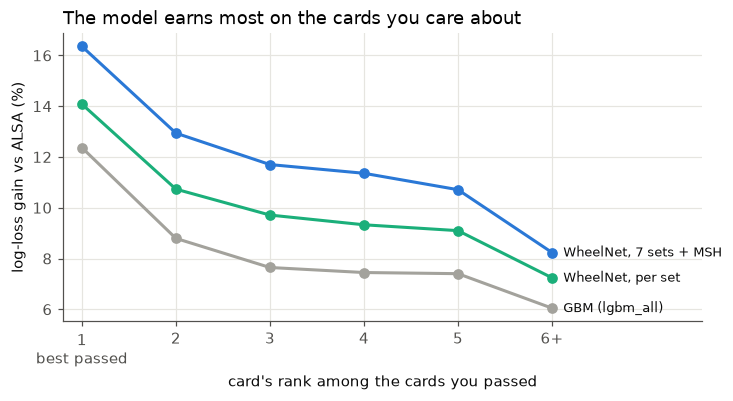

rank,n,wheel rate,ALSA logloss,lgbm_all,wheelnet,wheelnet_multiset_plus_target
i64,i64,f64,f64,f64,f64,f64
1,185256,0.036916,0.156082,0.123672,0.140818,0.163567
2,185256,0.07345,0.256935,0.087923,0.107321,0.129382
3,185256,0.115208,0.349632,0.076458,0.097113,0.117005
4,185256,0.161452,0.431812,0.074478,0.093283,0.113571
5,185256,0.210012,0.500699,0.074026,0.090976,0.107102
6,1018812,0.527855,0.575459,0.060444,0.072402,0.082357


In [18]:
sys.path.insert(0, str(ROOT / "scripts"))
from wheel_breakdown import load
models = ["wheelnet", "wheelnet_multiset_plus_target"]
bd, bd_names = load(SET, models)
bd = bd.drop_nulls(bd_names).with_columns(pl.col("rank_in_pack").clip(upper_bound=6).alias("r"))

def ll(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return float(-(y * np.log(p) + (1 - y) * np.log(1 - p)).mean())

rows = []
for r, g in bd.group_by("r"):
    y = g["wheeled"].to_numpy()
    a = ll(y, g["alsa_ata_logreg"].to_numpy())
    rows.append({"rank": r[0], "n": g.height, "wheel rate": y.mean(), "ALSA logloss": a,
                 **{m: 1 - ll(y, g[m].to_numpy()) / a for m in ["lgbm_all", *models]}})
by_rank = pl.DataFrame(rows).sort("rank")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
x = by_rank["rank"].to_numpy()
for m, c, lab in [("wheelnet_multiset_plus_target", BLUE, "WheelNet, 7 sets + MSH"),
                  ("wheelnet", AQUA, "WheelNet, per set"), ("lgbm_all", GRAY, "GBM (lgbm_all)")]:
    v = by_rank[m].to_numpy() * 100
    ax.plot(x, v, color=c, marker="o", ms=6, label=lab)
    ax.text(6.12, v[-1], lab, color=INK, fontsize=8.5, va="center")
ax.set_xticks(x, ["1\nbest passed", "2", "3", "4", "5", "6+"]); ax.set_xlim(0.8, 7.6)
ax.set_xlabel("card's rank among the cards you passed"); ax.set_ylabel("log-loss gain vs ALSA (%)")
ax.set_title("The model earns most on the cards you care about", loc="left")
plt.show()
by_rank

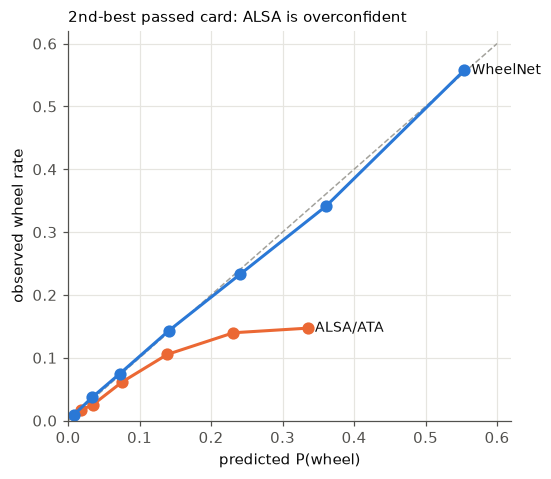

model,b,share,pred,real
str,enum,f64,f32,f64
"""ALSA/ATA""","""(-inf, 0.02]""",0.04503,0.01787,0.016902
"""ALSA/ATA""","""(0.02, 0.05]""",0.162904,0.034327,0.025084
"""ALSA/ATA""","""(0.05, 0.1]""",0.396187,0.075803,0.061734
"""ALSA/ATA""","""(0.1, 0.2]""",0.327309,0.138801,0.105399
"""ALSA/ATA""","""(0.2, 0.3]""",0.060673,0.231331,0.139858
"""ALSA/ATA""","""(0.3, 0.5]""",0.007849,0.335269,0.14718
"""WheelNet""","""(-inf, 0.02]""",0.304325,0.008039,0.009223
"""WheelNet""","""(0.02, 0.05]""",0.233957,0.03352,0.036939
"""WheelNet""","""(0.05, 0.1]""",0.206557,0.072059,0.074453


In [19]:
# calibration on the 2nd-best passed card: ALSA vs WheelNet, fixed probability buckets
edges = [0, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 1]
r2 = bd.filter(pl.col("rank_in_pack") == 2)
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.plot([0, 0.6], [0, 0.6], color=GRAY, lw=1, ls="--")
cal = []
for m, c, lab in [("alsa_ata_logreg", ORANGE, "ALSA/ATA"), ("wheelnet_multiset_plus_target", BLUE, "WheelNet")]:
    q = (r2.with_columns(pl.col(m).cut(edges[1:-1]).alias("b")).group_by("b")
           .agg(pl.len().alias("n"), pl.col(m).mean().alias("pred"), pl.col("wheeled").mean().alias("real"))
           .filter(pl.col("n") >= 200).sort("pred"))
    ax.plot(q["pred"], q["real"], color=c, marker="o", ms=7)
    ax.text(q["pred"][-1] + 0.01, q["real"][-1], lab, color=INK, fontsize=9, va="center")
    cal.append(q.with_columns(pl.lit(lab).alias("model"), (pl.col("n") / r2.height).alias("share")))
ax.set_xlim(0, 0.62); ax.set_ylim(0, 0.62)
ax.set_xlabel("predicted P(wheel)"); ax.set_ylabel("observed wheel rate")
ax.set_title("2nd-best passed card: ALSA is overconfident", loc="left", fontsize=10)
plt.show()
pl.concat(cal).select("model", "b", "share", "pred", "real")

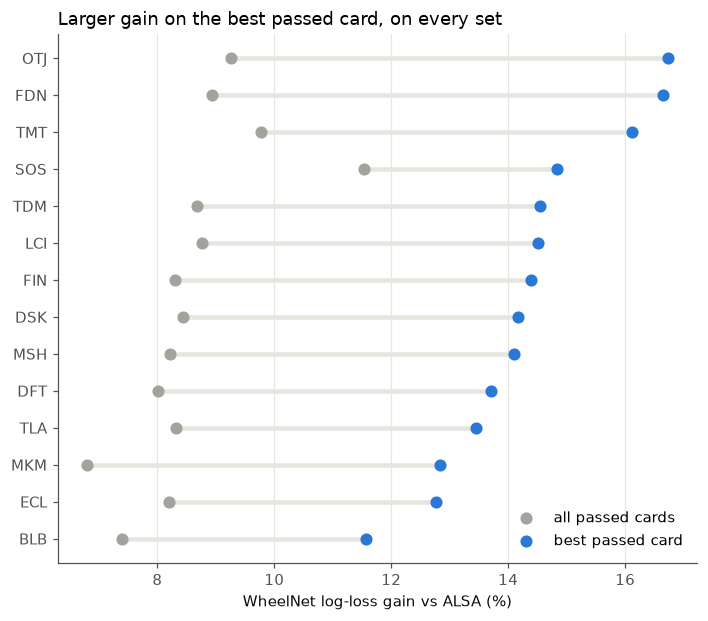

set,all cards,best passed,rank 2,"ECE top-3, ALSA","ECE top-3, WheelNet"
str,f64,f64,f64,f64,f64
"""BLB""",0.073933,0.115637,0.092347,0.017233,0.005333
"""DFT""",0.080078,0.137034,0.10603,0.018633,0.004733
"""DSK""",0.084324,0.141593,0.105374,0.017633,0.004333
"""ECL""",0.082061,0.12769,0.096887,0.0183,0.003267
"""FDN""",0.089293,0.166419,0.113814,0.0206,0.004267
"""FIN""",0.083001,0.143868,0.105187,0.025267,0.006633
"""LCI""",0.087654,0.145056,0.107795,0.029,0.008533
"""MKM""",0.067927,0.128358,0.095004,0.0205,0.003867
"""MSH""",0.082091,0.140935,0.107046,0.024333,0.0039


In [20]:
# the same pattern on every set (per-set WheelNet; the pretrained model exists only for MSH)
rows = []
for f in sorted((ROOT / "results").glob("*.PremierDraft/wheel_breakdown.json")):
    r = json.load(open(f))
    if "wheelnet" not in r["all"]:
        continue
    g = lambda s: 1 - r[s]["wheelnet"]["logloss"] / r[s]["alsa_ata_logreg"]["logloss"]
    ece = lambda m: np.mean([r[f"rank{k}"][m]["ece"] for k in (1, 2, 3)])
    rows.append({"set": f.parent.name.split(".")[0], "all cards": g("all"), "best passed": g("rank1"),
                 "rank 2": g("rank2"), "ECE top-3, ALSA": ece("alsa_ata_logreg"), "ECE top-3, WheelNet": ece("wheelnet")})
xs = pl.DataFrame(rows).sort("best passed")
fig, ax = plt.subplots(figsize=(7.5, 0.36 * xs.height + 1.2))
yy = np.arange(xs.height)
ax.hlines(yy, xs["all cards"] * 100, xs["best passed"] * 100, color=GRID, lw=3)
ax.scatter(xs["all cards"] * 100, yy, color=GRAY, s=48, zorder=3, label="all passed cards")
ax.scatter(xs["best passed"] * 100, yy, color=BLUE, s=48, zorder=3, label="best passed card")
ax.set_yticks(yy, xs["set"]); ax.grid(axis="y", visible=False)
ax.set_xlabel("WheelNet log-loss gain vs ALSA (%)")
ax.legend(loc="lower right"); ax.set_title("Larger gain on the best passed card, on every set", loc="left")
plt.show()
xs.sort("set")

What this shows:
1. **The gain over ALSA is largest for the best passed card** (+12–17% across sets, against +7–12% over all
   cards), and it falls with rank. The fate of a strong passed card depends on the table, not on the card.
2. **ALSA is overconfident about your good cards.** It is calibrated on average but 3–6× worse calibrated on the
   top three passed cards. ALSA is a per-card average over every pack the card appears in. Being the best card
   *you* pass usually means the pack is thin, so little else absorbs the other seven picks.
3. **For a top-3 card the answer is almost always "no".** WheelNet puts ≥ 50% on under 1% of them. Its value is
   separating 1% from 25%: a third of rank-2 cards get < 2% and really wheel ~1%, while the 9% it puts above 20%
   wheel ~26% of the time.

# Part 2: WheelNet QA: what the model sees on the test set, and what it predicts

A walk through held-out **test** drafts (the last 15% of MSH drafts by time, never used for training or
model selection):

1. The test set at a glance, and the model's overall scores on it
2. One draft through the model's eyes: every input it gets, pick by pick
3. Predictions for a few packs of that draft, against what actually came back
4. Sanity checks: calibration, "does it predict the right number of cards wheeling?", per-pick accuracy
5. Where it is most wrong, and which cards it thinks wheel
6. What the time input does: the same pack scored on different days of the format

Uses `models/wheelnet_time.pt` when it exists (trained with the days-into-format input), otherwise
`models/wheelnet.pt`. Change `DRAFT` / `PACKS` in section 2 to look at other drafts. Runs on CPU in a few
minutes; needs about 10GB of free memory to load MSH.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
from matplotlib.patches import Patch

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from openlane.data import COLORS, N_PACKS, N_SEATS, load_tensors
from openlane.evaluate import metrics
from openlane.features import wheel_tensors
from openlane.nn import DraftDataset, WheelNet, collate, draft_context
import pickle

SET, EVENT = "MSH", "PremierDraft"
OUT = ROOT / "results" / f"{SET}.{EVENT}"
MODEL = "wheelnet_time" if (OUT / "models" / "wheelnet_time.pt").exists() else "wheelnet"

# same categorical palette as wheelnet.ipynb, fixed order
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"
GRAY, INK, MUTED, SURFACE, GRID = "#a3a29c", "#0b0b0b", "#52514e", "#fcfcfb", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pl.Config.set_tbl_rows(50); pl.Config.set_fmt_str_lengths(200); pl.Config.set_tbl_width_chars(250)

t = load_tensors(SET, EVENT)
passed, back = wheel_tensors(t)
splits = pickle.load(open(ROOT / "data" / "features" / f"{SET}.{EVENT}" / "meta.pkl", "rb"))["splits"]
ckpt = torch.load(OUT / "models" / f"{MODEL}.pt", map_location="cpu", weights_only=False)
model = WheelNet(len(t.names), card_feats=ckpt["card_feats"], **ckpt["cfg"]).eval()
model.load_state_dict(ckpt["state"])
inputs = ckpt.get("inputs")  # None for models trained before per-draft context existed
ctx_all = draft_context(t, **inputs) if inputs and ckpt["cfg"].get("n_ctx") else None

ts = np.array(t.draft_time, dtype="datetime64[s]")
days = (ts - ts.min()).astype(np.float64) / 86400   # what the time input is built from
n, W = t.n_picks, t.n_picks - N_SEATS                # picks per pack, wheel-eligible picks per pack
RANKS = ["unknown", "bronze", "silver", "gold", "platinum", "diamond", "mythic"]
print(f"model: {MODEL}  extra inputs: {inputs or 'none'}")

model: wheelnet_time  extra inputs: {'rank': False, 'skill': False, 'time': True}


## 1. The test set at a glance

The model is scored on a random sample of test drafts (all of them would take longer on CPU and give the
same picture). A card "wheels" if it is still in the pack when that pack comes back to you, 8 picks later.
Only picks 1-6 of each pack can wheel in a 14-card pack, so those are the only picks scored.

In [2]:
test = splits["test"]
rng = np.random.default_rng(0)
sample = np.sort(rng.choice(test, 2000, replace=False))
ds = DraftDataset(t, passed, back, sample, ctx_all)

def predict(ds, batch=64):
    out = []
    with torch.no_grad():
        for i in range(0, len(ds), batch):
            *x, label, mask, ctx = collate([ds[j] for j in range(i, min(i + batch, len(ds)))])
            out.append(torch.sigmoid(model(*x, mask, ctx)).numpy())
    return np.concatenate(out)

prob = predict(ds)
m = metrics(ds.label[ds.mask], prob[ds.mask])
tr = splits["train"]
summary = {
    "train drafts": len(tr), "test drafts": len(test), "scored here": len(sample),
    "train period": f"{t.draft_time[tr[0]][:10]} .. {t.draft_time[tr[-1]][:10]}  (days {days[tr[0]]:.0f}-{days[tr[-1]]:.0f})",
    "test period": f"{t.draft_time[test[0]][:10]} .. {t.draft_time[test[-1]][:10]}  (days {days[test[0]]:.0f}-{days[test[-1]]:.0f})",
    "passed cards scored": int(ds.mask.sum()),
    "share that wheeled": f"{ds.label[ds.mask].mean():.1%}",
    **{k: round(float(v), 4) for k, v in m.items()},
}
pl.DataFrame({"": list(summary), "value": [str(v) for v in summary.values()]})

,value
str,str
"""train drafts""","""48026"""
"""test drafts""","""10292"""
"""scored here""","""2000"""
"""train period""","""2026-06-23 .. 2026-07-10 (days 0-17)"""
"""test period""","""2026-07-16 .. 2026-07-24 (days 23-31)"""
"""passed cards scored""","""377983"""
"""share that wheeled""","""33.3%"""
"""logloss""","""0.4224"""
"""brier""","""0.1382"""


## 2. One draft through the model's eyes

Pick any test draft. The table is **everything the model has seen by the time it scores the chosen pick**,
one row per pick (the model reads this as one history token per row):

* **pack shown**: every card in the pack at that pick (inside the model this row's pack is a
  count-weighted average of card embeddings; the pack being *scored* is not averaged, see section 3)
* **took**: the card the drafter picked (kept as an individual card)
* **others took**: from pick 9 on, the pack you see is one you passed 8 picks earlier coming back, so the
  model also gets the cards the other 7 drafters took out of it. At those picks the **pack shown is
  exactly the cards that wheeled**.

Rank is shown for context; the model only gets the inputs listed above the table.

In [3]:
DRAFT = 0                                # index into the test sample
PACKS = [(0, 1), (0, 5), (1, 2), (2, 0)]  # (pack, pick), 0-based: P1p2, P1p6, P2p3, P3p1

d = sample[DRAFT]
def card_list(idx, cnt):
    return ", ".join(t.names[c] + (f" x{k}" if k > 1 else "") for c, k in zip(idx, cnt) if k > 0)

def history(i, k_end, p_end):
    rows = []
    for k in range(N_PACKS):
        for p in range(n):
            if (k, p) > (k_end, p_end):
                return pl.DataFrame(rows)
            s = k * n + p
            rows.append({
                "pick": f"P{k+1}p{p+1}", "cards": int(ds.pack_n[i, s].sum()),
                "took": t.names[ds.pick[i, s]],
                "others took": card_list(ds.oth[i, s], ds.oth_n[i, s]) if p >= N_SEATS else "",
                "pack shown": card_list(ds.pack[i, s], ds.pack_n[i, s]),
            })
    return pl.DataFrame(rows)

print(f"test draft {d}: drafted {t.draft_time[d]}, day {days[d]:.1f} of the format, rank {RANKS[int(t.rank[d]) + 1]}")
if ctx_all is not None:
    print(f"per-draft input vector the model gets: {np.round(ctx_all[d], 3).tolist()}  ({inputs})")
k_last, p_last = PACKS[-1]
history(DRAFT, k_last, p_last)

test draft 58318: drafted 2026-07-16 22:27:53, day 23.3 of the format, rank silver
per-draft input vector the model gets: [0.7760000228881836, 0.9290000200271606]  ({'rank': False, 'skill': False, 'time': True})


pick,cards,took,others took,pack shown
str,i64,str,str,str
"""P1p1""",14,"""Vision Quest""","""""","""Agent 13, Sharon Carter, Agent of Atlas, Armor Wars, Call Damage Control, Final Act, Futurist Forge, HYDRA Assault Robot, K'un-Lun Warrior, Killmonger, Scourge of Wakanda, Ninja of the Hand, Plains, P…"
"""P1p2""",13,"""We Say Thee Nay!""","""""","""Beast, Erudite Aerialist, Hex Magic, Island, Jessica Jones, Private Eye, Kingpin's Enforcers, Mockingbird, Ace Agent, Pet Avengers, S.H.I.E.L.D. Spy Kit, Super Suit, Titania, Rugged Rumbler, Volcanic …"
"""P1p3""",12,"""Super Intelligence""","""""","""Atlantis Attacks, Crossbones, Malicious Mercenary, HYDRA Troopers, Hawkeye, Young Avenger, Hour of Defeat, Kree Sentinel, Mountain, Murdock's Crusade, Super Intelligence, Surveillance Room, Undercover…"
"""P1p4""",11,"""Stark Industries""","""""","""Atlantean Cavalry, Bold Biochemist, Brave Brawler, Castle Doom, Crimson Operative, Decoy Ploy, Hercules, Prince of Power, Knight of Wundagore, Savage Land Dinosaur, Stark Industries, Ultron Drone"""
"""P1p5""",10,"""Atlantis Attacks""","""""","""Atlantis Attacks, Giant Growth, HULK SMASH!, Madame Hydra, Panther Pounce, Red Room Recruit, Subterranean Cavern, Super Suit, Thirst for Knowledge, Villainous Hideout"""
"""P1p6""",9,"""Gleaming Bastion""","""""","""A.I.M. Synthoids, Brave Brawler, Gleaming Bastion, Hawkeye's Bow, Helicarrier Strike, I Am Iron Man, Pet Avengers, Stolen Stark Tech, Swamp"""
"""P1p7""",8,"""Volcanic Villain""","""""","""Call Damage Control, Giant Growth, HULK SMASH!, Ninja of the Hand, Pym Technologies, Swordsman, Sharp Scoundrel, Visions of Villainy, Volcanic Villain"""
"""P1p8""",7,"""Moonstone, Harsh Mistress""","""""","""A.I.M. Synthoids, Hire a Crew, Kree Sentinel, Moonstone, Harsh Mistress, Ninja of the Hand, Plains, Thunderbolts Conspiracy"""
"""P1p9""",6,"""Armor Wars""","""Agent 13, Sharon Carter, Final Act, Futurist Forge, HYDRA Assault Robot, Killmonger, Scourge of Wakanda, Pym Particles, Wonder Man, Hollywood Hero""","""Agent of Atlas, Armor Wars, Call Damage Control, K'un-Lun Warrior, Ninja of the Hand, Plains"""


## 3. Predictions for a few packs

For each chosen pick: the cards the drafter **passed** (the pack minus their pick), each scored by the model
with P(it comes back 8 picks later). Every passed card is its own token here, so the model scores each card
knowing exactly which other cards are next to it. Blue bars came back, gray bars were taken by the table.

The subtitle compares the number of cards the model expects back (sum of probabilities) with how many
actually came back. The returning pack size is fixed (6 - pick cards in a 14-card pack), and the model is
never told that, so a match is a good sign it has learned the table's behaviour rather than per-card rates.

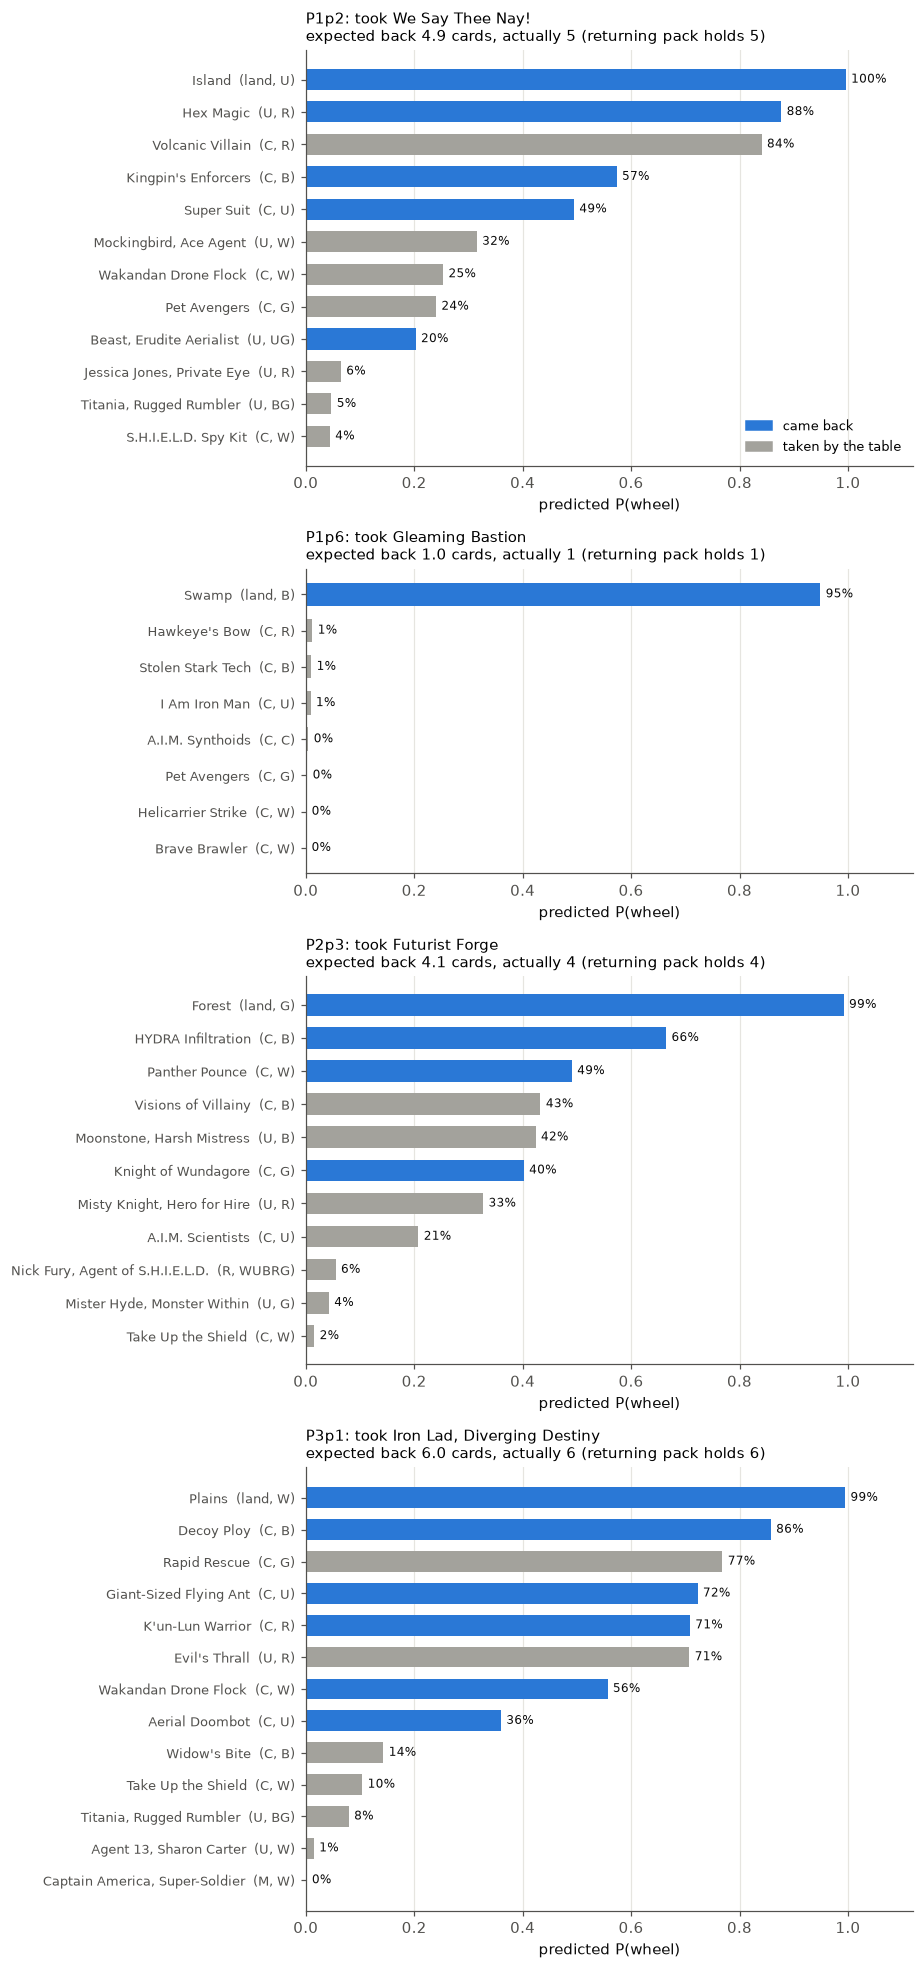

In [4]:
def label(c):
    r = {"common": "C", "uncommon": "U", "rare": "R", "mythic": "M", "basic": "land"}.get(t.meta["rarity"][int(c)], "S")
    col = "".join(x for x in COLORS if t.meta[x][int(c)]) or "C"
    return f"{t.names[c]}  ({r}, {col})"

def show_pack(i, k, p, ax):
    msk = ds.mask[i, k, p]
    idx, pr, lab, cp = ds.idx[i, k, p][msk], prob[i, k, p][msk], ds.label[i, k, p][msk], ds.copies[i, k, p][msk]
    o = np.argsort(pr)
    ax.barh(range(len(o)), pr[o], color=[BLUE if lab[j] else GRAY for j in o], height=0.65)
    ax.set_yticks(range(len(o)), [label(idx[j]) + (f" x{cp[j]}" if cp[j] > 1 else "") for j in o], fontsize=8.5)
    for y, j in enumerate(o):
        ax.text(pr[j] + 0.01, y, f"{pr[j]:.0%}", va="center", fontsize=8, color=INK)
    ax.set_xlim(0, 1.12); ax.grid(axis="y", visible=False); ax.set_xlabel("predicted P(wheel)")
    took = t.names[t.pick[sample[i], k, p]]
    ax.set_title(f"P{k+1}p{p+1}: took {took}\nexpected back {pr.sum():.1f} cards, actually {lab.sum()} "
                 f"(returning pack holds {int(back[sample[i], k, p].sum())})", loc="left", fontsize=9.5)

fig, axes = plt.subplots(len(PACKS), 1, figsize=(8.5, sum(0.3 * ds.mask[DRAFT, k, p].sum() + 1.2 for k, p in PACKS)),
                         gridspec_kw={"height_ratios": [ds.mask[DRAFT, k, p].sum() + 3 for k, p in PACKS]})
for ax, (k, p) in zip(np.atleast_1d(axes), PACKS):
    show_pack(DRAFT, k, p, ax)
axes[0].legend(handles=[Patch(color=BLUE, label="came back"), Patch(color=GRAY, label="taken by the table")],
               loc="lower right", fontsize=8.5)
plt.tight_layout(); plt.show()

Same packs as a table, with what came back at pick +8 (the pack shown at that later pick).

In [5]:
rows = []
for k, p in PACKS:
    msk = ds.mask[DRAFT, k, p]
    for c, pr, lab in zip(ds.idx[DRAFT, k, p][msk], prob[DRAFT, k, p][msk], ds.label[DRAFT, k, p][msk]):
        rows.append({"pick": f"P{k+1}p{p+1}", "card": t.names[c], "P(wheel)": round(float(pr), 3),
                     "came back": bool(lab), "returned at": f"P{k+1}p{p+9}"})
pl.DataFrame(rows).sort(["pick", "P(wheel)"], descending=[False, True])

pick,card,P(wheel),came back,returned at
str,str,f64,bool,str
"""P1p2""","""Island""",0.996,true,"""P1p10"""
"""P1p2""","""Hex Magic""",0.877,true,"""P1p10"""
"""P1p2""","""Volcanic Villain""",0.841,false,"""P1p10"""
"""P1p2""","""Kingpin's Enforcers""",0.573,true,"""P1p10"""
"""P1p2""","""Super Suit""",0.495,true,"""P1p10"""
"""P1p2""","""Mockingbird, Ace Agent""",0.315,false,"""P1p10"""
"""P1p2""","""Wakandan Drone Flock""",0.253,false,"""P1p10"""
"""P1p2""","""Pet Avengers""",0.24,false,"""P1p10"""
"""P1p2""","""Beast, Erudite Aerialist""",0.203,true,"""P1p10"""


## 4. Sanity checks on the whole test sample

* **Calibration**: of the cards given ~30%, do ~30% come back? Points on the diagonal mean the
  probabilities can be read at face value.
* **Cards expected back per pack**: average sum of probabilities vs the true number of distinct cards that
  came back, by pick.
* **Per-pick log loss** against a simple baseline: each card's wheel rate at that pick in the training
  drafts (what an ALSA-style lookup knows).

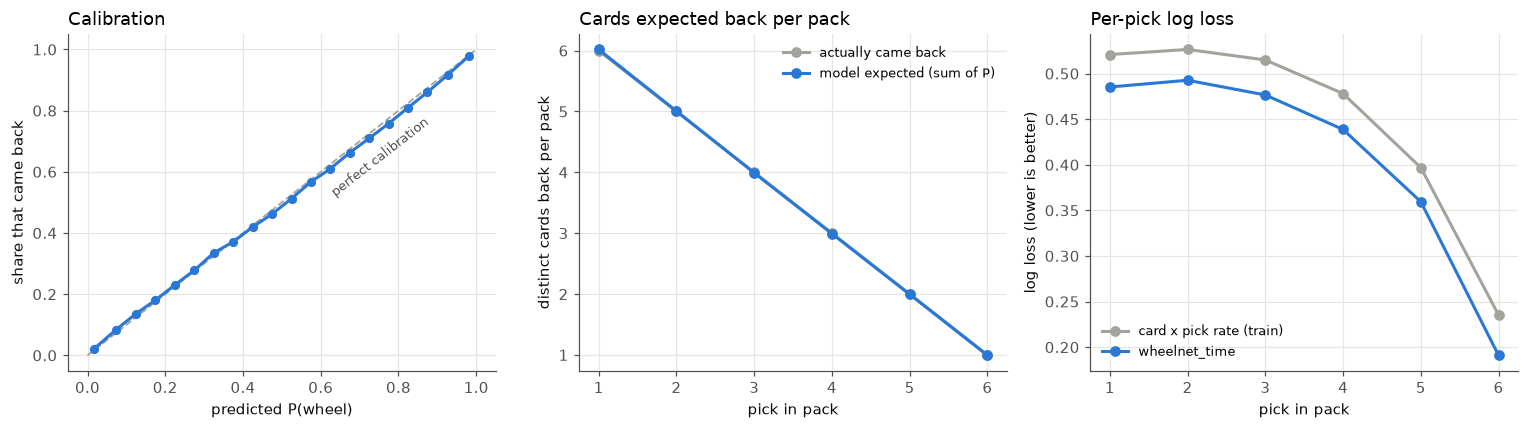

pick,expected,actual,model,baseline
i64,f64,f64,f64,f64
1,6.019,5.9998,0.4853,0.5209
2,5.0062,5.0,0.4927,0.5265
3,3.9914,3.9998,0.4765,0.515
4,2.9929,3.0,0.4387,0.478
5,1.9962,2.0,0.3594,0.3969
6,0.9933,1.0,0.191,0.2352


In [6]:
y, q = ds.label[ds.mask], prob[ds.mask]
bins = np.linspace(0, 1, 21)
b = np.clip(np.digitize(q, bins) - 1, 0, 19)
cal = pl.DataFrame({"b": b, "q": q, "y": y}).group_by("b").agg(pl.col("q").mean(), pl.col("y").mean(), pl.len()).sort("b")

# per card x pick wheel rate in the training drafts
trs = slice(tr[0], tr[-1] + 1)
seen = (passed[trs] > 0).sum((0, 1)).T.astype(np.float64)
came = (back[trs] > 0).sum((0, 1)).T.astype(np.float64)
rate = (came + 20 * came.sum(0) / seen.sum(0)) / (seen + 20)
base = rate[ds.idx.clip(max=len(t.names) - 1), np.arange(W)[None, None, :, None]]

def ll(y, q):
    q = np.clip(q, 1e-6, 1 - 1e-6)
    return float(-(y * np.log(q) + (1 - y) * np.log(1 - q)).mean())

per_pick = []
for p in range(W):
    mk = ds.mask[:, :, p]
    per_pick.append({"pick": p + 1, "expected": (prob[:, :, p] * ds.mask[:, :, p]).sum(-1).mean(),
                     "actual": ds.label[:, :, p].sum(-1).mean(),
                     "model": ll(ds.label[:, :, p][mk], prob[:, :, p][mk]),
                     "baseline": ll(ds.label[:, :, p][mk], base[:, :, p][mk])})
pp = pl.DataFrame(per_pick)

fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(14, 4))
a1.plot([0, 1], [0, 1], color=GRAY, lw=1.2, ls="--")
a1.plot(cal["q"], cal["y"], color=BLUE, marker="o", ms=5)
a1.set_xlabel("predicted P(wheel)"); a1.set_ylabel("share that came back"); a1.set_title("Calibration", loc="left")
a1.text(0.62, 0.52, "perfect calibration", color=MUTED, fontsize=8.5, rotation=38)

x = pp["pick"].to_numpy()
a2.plot(x, pp["actual"], color=GRAY, marker="o", ms=6, label="actually came back")
a2.plot(x, pp["expected"], color=BLUE, marker="o", ms=6, label="model expected (sum of P)")
a2.set_xlabel("pick in pack"); a2.set_ylabel("distinct cards back per pack")
a2.set_title("Cards expected back per pack", loc="left"); a2.legend(fontsize=8.5)

a3.plot(x, pp["baseline"], color=GRAY, marker="o", ms=6, label="card x pick rate (train)")
a3.plot(x, pp["model"], color=BLUE, marker="o", ms=6, label=MODEL)
a3.set_xlabel("pick in pack"); a3.set_ylabel("log loss (lower is better)")
a3.set_title("Per-pick log loss", loc="left"); a3.legend(fontsize=8.5)
plt.tight_layout(); plt.show()
pp.with_columns(pl.col(pl.Float64).round(4))

## 5. Where it is most wrong, and which cards it thinks wheel

Confident misses: cards the model was sure would come back that the table took, and cards it was sure would
be taken that came back. A handful of these is expected at these volumes (a 95% call is wrong 1 time in 20).
Basic lands are left out of the tables in this section: they wheel ~97% of the time, so the top "misses"
would all be someone taking a basic.

In [7]:
i, k, p, j = np.nonzero(ds.mask)
flat = pl.DataFrame({
    "draft": sample[i], "pick": [f"P{a+1}p{b+1}" for a, b in zip(k, p)],
    "card": [t.names[c] for c in ds.idx[i, k, p, j]], "P(wheel)": prob[i, k, p, j],
    "came back": ds.label[i, k, p, j], "baseline": base[i, k, p, j],
    "basic": t.meta["rarity"].to_numpy()[ds.idx[i, k, p, j]] == "basic",
})
nb = flat.filter(~pl.col("basic")).drop("basic")
print("Sure it would come back, but it was taken:")
display(nb.filter(~pl.col("came back")).sort("P(wheel)", descending=True).head(8))
print("Sure it would be taken, but it came back:")
display(nb.filter(pl.col("came back")).sort("P(wheel)").head(8))

Sure it would come back, but it was taken:


draft,pick,card,P(wheel),came back,baseline
i64,str,str,f32,bool,f64
66182,"""P2p1""","""Hire a Crew""",0.977433,false,0.8875
61146,"""P1p1""","""Hire a Crew""",0.974293,false,0.8875
67934,"""P1p1""","""Super Speed""",0.97123,false,0.882259
63777,"""P3p1""","""Super Strength""",0.969998,false,0.873201
58725,"""P2p1""","""Hire a Crew""",0.967974,false,0.8875
67333,"""P2p1""","""Super Speed""",0.966223,false,0.882259
67424,"""P1p1""","""Hire a Crew""",0.965926,false,0.8875
59140,"""P1p2""","""Super Speed""",0.965472,false,0.830106


Sure it would be taken, but it came back:


draft,pick,card,P(wheel),came back,baseline
i64,str,str,f32,bool,f64
60414,"""P3p6""","""Viv Vision, Teen Synthezoid""",0.000838,true,0.004962
58578,"""P1p5""","""Take Up the Shield""",0.001218,true,0.051642
59834,"""P1p6""","""Red Hulk""",0.001343,true,0.017281
67054,"""P1p6""","""Wakandan Drone Flock""",0.001587,true,0.054695
61169,"""P1p4""","""Namor the Sub-Mariner""",0.001747,true,0.034336
67785,"""P2p5""","""Brave Brawler""",0.001825,true,0.06135
67663,"""P1p6""","""We Say Thee Nay!""",0.001903,true,0.019488
66313,"""P2p6""","""Red Hulk""",0.001907,true,0.017281


Per card over the test sample (cards passed at least 150 times): the model's average prediction next to the
actual wheel rate. Note the averages mix picks, so they are not comparable across cards; what matters is
how close the two columns are for each card.

In [8]:
cards = (nb.group_by("card")
         .agg(pl.len().alias("times passed"), pl.col("P(wheel)").mean().alias("mean predicted"),
              pl.col("came back").mean().alias("actual rate"))
         .filter(pl.col("times passed") >= 150)
         .with_columns((pl.col("mean predicted") - pl.col("actual rate")).alias("gap"))
         .with_columns(pl.col(pl.Float64).round(3)))
print("Most likely to wheel:"); display(cards.sort("mean predicted", descending=True).head(10))
print("Least likely to wheel:"); display(cards.sort("mean predicted").head(10))
print("Biggest gaps between prediction and reality:"); display(cards.sort(pl.col("gap").abs(), descending=True).head(10))

Most likely to wheel:


card,times passed,mean predicted,actual rate,gap
str,u32,f32,f64,f64
"""Hire a Crew""",3401,0.731603,0.724,0.007
"""Super Speed""",3400,0.703573,0.685,0.019
"""Super Strength""",3285,0.67147,0.671,0.001
"""Volcanic Villain""",3405,0.638795,0.623,0.015
"""Call Damage Control""",3431,0.622,0.621,0.001
"""Vision of Love""",3266,0.615453,0.619,-0.004
"""Hex Magic""",1391,0.593658,0.585,0.008
"""Project Deathlok Soldier""",3398,0.582714,0.573,0.009
"""Blazing Crescendo""",3252,0.568168,0.539,0.029


Least likely to wheel:


card,times passed,mean predicted,actual rate,gap
str,u32,f32,f64,f64
"""Web Up""",807,0.003373,0.001,0.002
"""Super Villain Lockup""",491,0.00528,0.002,0.003
"""Spider-Woman, Secret Agent""",442,0.005982,0.007,-0.001
"""The Sentry, Golden Guardian""",204,0.008643,0.005,0.004
"""Red Guardian, Super-Soldier""",468,0.01046,0.009,0.002
"""Dark Deed""",390,0.010798,0.005,0.006
"""Agent 13, Sharon Carter""",383,0.012186,0.008,0.004
"""Justice, Vance Astrovik""",326,0.01236,0.018,-0.006
"""Hero in Training""",1016,0.012613,0.013,-0.0


Biggest gaps between prediction and reality:


card,times passed,mean predicted,actual rate,gap
str,u32,f32,f64,f64
"""Iron Fist, Living Weapon""",1213,0.439932,0.355,0.085
"""Giant-Sized Flying Ant""",3024,0.227711,0.303,-0.076
"""Speedball, New Warrior""",1179,0.344076,0.276,0.068
"""Hawkeye, Young Avenger""",1054,0.264908,0.198,0.067
"""Gleaming Bastion""",389,0.039189,0.098,-0.058
"""Avengers Hangar""",1591,0.181126,0.236,-0.055
"""Ronin, Shadow Stalker""",1209,0.447671,0.397,0.051
"""Ghost, Spectral Saboteur""",1217,0.274456,0.224,0.051
"""The Thing, Ben Grimm""",1061,0.232881,0.183,0.05


## 6. What the time input does

The same pack from section 3, re-scored as if it had been drafted on a different day of the format
(everything else identical). The five cards whose prediction moves most are shown. The shaded region is
later than any training draft, so there the model is extrapolating. Skipped for models without the time
input.

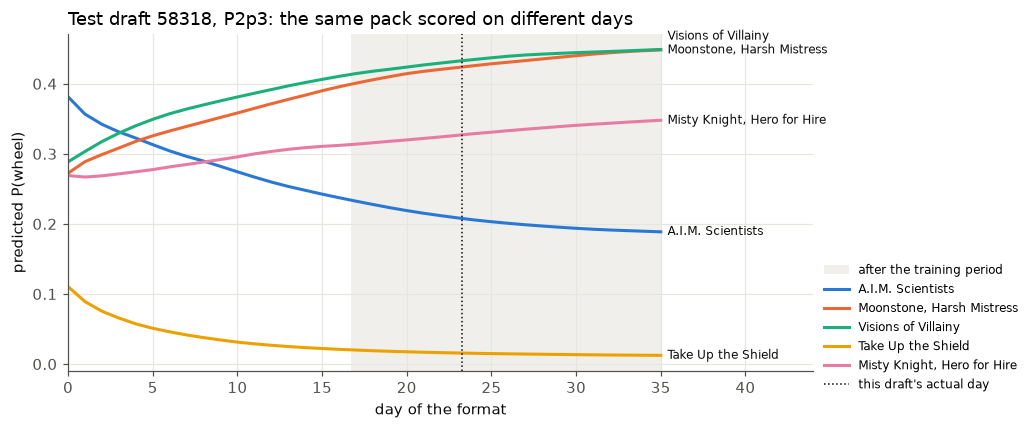

In [9]:
if ctx_all is None or not inputs.get("time"):
    print(f"{MODEL} has no time input")
else:
    k, p = PACKS[2]
    grid = np.arange(0, 36, 1.0)
    x = collate([ds[DRAFT]] * len(grid))
    ctx = x[-1].clone()
    ctx[:, -2] = torch.tensor(grid / 30)                         # same encoding as draft_context
    ctx[:, -1] = torch.tensor(np.log1p(grid) / np.log1p(30))
    with torch.no_grad():
        pr = torch.sigmoid(model(*x[:7], x[8], ctx))[:, k, p].numpy()   # [days, slots]
    msk = ds.mask[DRAFT, k, p]
    idx = ds.idx[DRAFT, k, p][msk]; pr = pr[:, msk]
    top = np.argsort(-(pr.max(0) - pr.min(0)))[:5]
    fig, ax = plt.subplots(figsize=(9.5, 4))
    ax.axvspan(days[tr[-1]], grid[-1], color=GRID, alpha=0.6, lw=0, label="after the training period")
    ys = {c: pr[-1, c] for c in top}  # end-of-line labels, nudged apart so they don't overlap
    gap = 0.045 * (pr[:, top].max() - pr[:, top].min())
    order = sorted(top, key=lambda c: ys[c])
    for a, b in zip(order, order[1:]):
        ys[b] = max(ys[b], ys[a] + gap)
    for c, col in zip(top, [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]):
        ax.plot(grid, pr[:, c], color=col, label=t.names[idx[c]])
        ax.text(grid[-1] + 0.4, ys[c], t.names[idx[c]], color=INK, fontsize=8, va="center")
    ax.axvline(days[d], color=INK, lw=1, ls=":", label="this draft's actual day")
    ax.set_xlim(0, grid[-1] + 9); ax.set_xlabel("day of the format"); ax.set_ylabel("predicted P(wheel)")
    ax.set_title(f"Test draft {d}, P{k+1}p{p+1}: the same pack scored on different days", loc="left")
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 0.35))
    plt.tight_layout(); plt.show()